# NLP Lab Assignment 7: Part-of-Speech (POS) Tagging for Hindi
**Course:** Natural Language Processing  
**Dataset:** Hindi BIS POS Tagged Corpus (`hindi-train-pos.txt`, `hindi-dev-pos.txt`, `hindi-test-pos.txt`)  
**Objective:**
1. Design a **Naive Bayes Classifier** for word-level POS tagging using 5 specified features:
   - Word length (binary: `"MORE"` if length $> 4$ else `"LESS"`)
   - Actual Word ($w_i$)
   - Previous Word ($w_{i-1}$)
   - Next Word ($w_{i+1}$)
   - Previous Tag ($t_{i-1}$)
2. Design a **Hidden Markov Model (HMM)** to predict the tag sequence given a sentence:
   - **Standard Forward Viterbi**
   - **Backward Viterbi**
   - **Forward-Backward Viterbi** (Max-Product Trellis Combination & Sum-Product Posterior Decoding)
3. Calculate transition, emission, and prior probabilities from the training set.
4. Evaluate all algorithms on both **Development** and **Test** splits.
5. Report per-tag Precision, Recall, and **F1-score**, generate comparative performance tables, and plot comprehensive charts.


In [1]:
# ==============================================================================
# 1. Imports and Global Configuration
# ==============================================================================
import os
import time
import math
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.special import logsumexp
from sklearn.metrics import classification_report, f1_score, accuracy_score, confusion_matrix

# Configure plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Segoe UI']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 1.0
plt.rcParams['figure.titlesize'] = 16
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Reproducibility
SEED = 42
np.random.seed(SEED)

print("Environment setup complete. All required libraries imported successfully.")


Environment setup complete. All required libraries imported successfully.


---
## 2. Dataset Loading & Exploratory Data Analysis

The dataset consists of Hindi sentences annotated with the **Bureau of Indian Standards (BIS)** POS tagset. Each line has the format `word\ttag`, and sentences are demarcated by empty lines.

### BIS POS Tagset Reference:
| Tag | Description | Tag | Description |
|:---|:---|:---|:---|
| **`N_NN`** | Common Noun | **`PR_PRP`** | Personal Pronoun |
| **`N_NNP`** | Proper Noun | **`PR_PRF`** | Reflexive Pronoun |
| **`N_NST`** | Spatiotemporal Noun | **`PR_PRL`** | Relative Pronoun |
| **`V_VM`** | Main Verb | **`PR_PRQ`** | Question Pronoun |
| **`V_VAUX`** | Auxiliary Verb | **`DM_DMD`** | Demonstrative |
| **`JJ`** | Adjective | **`PSP`** | Postposition |
| **`RB`** | Adverb | **`CC_CCD`** | Coordinating Conjunction |
| **`RP_RPD`** | Particle | **`CC_CCS`** | Subordinating Conjunction |
| **`RP_INTF`**| Intensifier | **`QT_QTC`** | Cardinal Quantifier |
| **`RP_NEG`** | Negation | **`QT_QTF`** | General Quantifier |
| **`RP_INJ`** | Interjection | **`QT_QTO`** | Ordinal Quantifier |
| **`RD_PUNC`**| Punctuation | **`RD_SYM`** | Symbol |


In [2]:
# ==============================================================================
# 2. Data Loading & Preprocessing
# ==============================================================================
def load_pos_data(filepath):
    """
    Loads POS-tagged corpus formatted as word\ttag with blank lines separating sentences.
    Returns:
        List of sentences, where each sentence is a list of (word, tag) tuples.
    """
    sentences = []
    current_sentence = []
    
    with open(filepath, 'r', encoding='utf-8') as f:
        for line in f:
            line = line.strip()
            if not line:
                if current_sentence:
                    sentences.append(current_sentence)
                    current_sentence = []
            else:
                parts = line.split('\t')
                if len(parts) != 2:
                    parts = line.split()
                if len(parts) >= 2:
                    current_sentence.append((parts[0], parts[1]))
                elif len(parts) == 1:
                    # In case of missing tag, fallback
                    current_sentence.append((parts[0], 'UNK'))
                    
    if current_sentence:
        sentences.append(current_sentence)
        
    return sentences

# File paths
train_path = "hindi-train-pos.txt"
dev_path = "hindi-dev-pos.txt"
test_path = "hindi-test-pos.txt"

# If running from another directory, fallback to current dir
if not os.path.exists(train_path):
    train_path = os.path.join("Assignment_7", "hindi-train-pos.txt")
    dev_path = os.path.join("Assignment_7", "hindi-dev-pos.txt")
    test_path = os.path.join("Assignment_7", "hindi-test-pos.txt")

train_data = load_pos_data(train_path)
dev_data = load_pos_data(dev_path)
test_data = load_pos_data(test_path)

# Extract vocabulary and tagsets
train_vocab = set(w for s in train_data for w, t in s)
dev_vocab = set(w for s in dev_data for w, t in s)
test_vocab = set(w for s in test_data for w, t in s)

all_tags = sorted(list(set(t for s in train_data for w, t in s)))
tag2idx = {t: i for i, t in enumerate(all_tags)}
idx2tag = {i: t for i, t in enumerate(all_tags)}
num_tags = len(all_tags)

# Summary statistics table
stats_df = pd.DataFrame([
    {
        "Split": "Train",
        "Sentences": len(train_data),
        "Tokens": sum(len(s) for s in train_data),
        "Unique Words": len(train_vocab),
        "Unique Tags": len(set(t for s in train_data for w, t in s)),
        "OOV Tokens (%)": 0.0,
        "OOV Types (%)": 0.0
    },
    {
        "Split": "Dev",
        "Sentences": len(dev_data),
        "Tokens": sum(len(s) for s in dev_data),
        "Unique Words": len(dev_vocab),
        "Unique Tags": len(set(t for s in dev_data for w, t in s)),
        "OOV Tokens (%)": sum(1 for s in dev_data for w, t in s if w not in train_vocab) / sum(len(s) for s in dev_data) * 100,
        "OOV Types (%)": len(dev_vocab - train_vocab) / len(dev_vocab) * 100
    },
    {
        "Split": "Test",
        "Sentences": len(test_data),
        "Tokens": sum(len(s) for s in test_data),
        "Unique Words": len(test_vocab),
        "Unique Tags": len(set(t for s in test_data for w, t in s)),
        "OOV Tokens (%)": sum(1 for s in test_data for w, t in s if w not in train_vocab) / sum(len(s) for s in test_data) * 100,
        "OOV Types (%)": len(test_vocab - train_vocab) / len(test_vocab) * 100
    }
])

print("Corpus Summary Statistics:")
display(stats_df)


Corpus Summary Statistics:


,Split,Sentences,Tokens,Unique Words,Unique Tags,OOV Tokens (%),OOV Types (%)
0,Train,15087,325710,18279,24,0.000000,0.000000
1,Dev,1866,40762,5814,24,4.187724,21.517028
2,Test,1910,41415,5873,24,4.585295,23.241955


C:\Users\paida\AppData\Local\Temp\ipykernel_23532\169279100.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tag_freq_df, x="Tag", y="Count", palette="Blues_r", ax=ax)


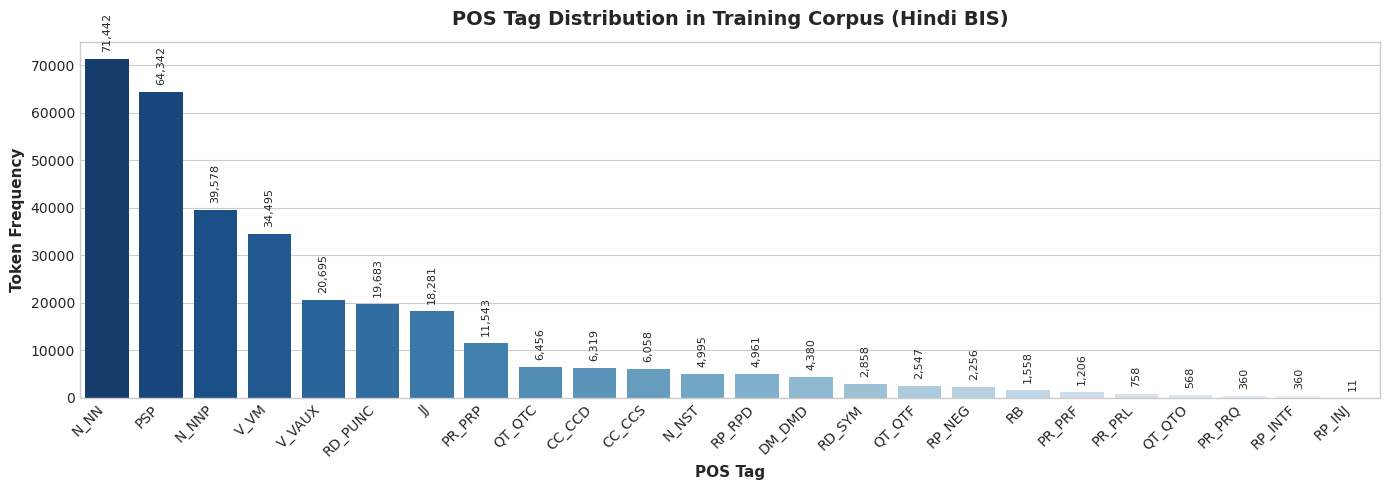

,Tag,Count,Frequency (%)
0,N_NN,71442,21.934236
1,PSP,64342,19.754383
2,N_NNP,39578,12.151300
3,V_VM,34495,10.590710
4,V_VAUX,20695,6.353812
5,RD_PUNC,19683,6.043106
6,JJ,18281,5.612662
7,PR_PRP,11543,3.543950
8,QT_QTC,6456,1.982131
9,CC_CCD,6319,1.940069


In [3]:
# ==============================================================================
# Tag Frequency Distribution
# ==============================================================================
train_tag_counts = Counter(t for s in train_data for w, t in s)
total_train_tokens = sum(train_tag_counts.values())

tag_freq_df = pd.DataFrame([
    {
        "Tag": t,
        "Count": train_tag_counts[t],
        "Frequency (%)": (train_tag_counts[t] / total_train_tokens) * 100
    }
    for t in all_tags
]).sort_values(by="Count", ascending=False).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(14, 5), dpi=100)
sns.barplot(data=tag_freq_df, x="Tag", y="Count", palette="Blues_r", ax=ax)
ax.set_title("POS Tag Distribution in Training Corpus (Hindi BIS)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("POS Tag", fontsize=11, fontweight="bold")
ax.set_ylabel("Token Frequency", fontsize=11, fontweight="bold")
plt.xticks(rotation=45, ha='right')
for p in ax.patches:
    ax.annotate(f"{int(p.get_height()):,}", 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=8, rotation=90, xytext=(0, 5),
                textcoords='offset points')
plt.tight_layout()
plt.show()

display(tag_freq_df.head(10))


In [4]:
# ==============================================================================
# Sample Sentences Inspection
# ==============================================================================
print("Sample Hindi Sentences with POS Tags from Training Data:\n" + "="*70)
for idx in [0, 1, 2]:
    sent = train_data[idx]
    tokens_str = " ".join([f"{w}/{t}" for w, t in sent])
    raw_text = " ".join([w for w, t in sent])
    print(f"Sentence {idx + 1} ({len(sent)} tokens):")
    print(f"  Text: {raw_text}")
    print(f"  Tags: {tokens_str}\n")


Sample Hindi Sentences with POS Tags from Training Data:
Sentence 1 (11 tokens):
  Text: यह एशिया की सबसे बड़ी मस्जिदों में से एक है ।
  Tags: यह/DM_DMD एशिया/N_NNP की/PSP सबसे/RP_INTF बड़ी/JJ मस्जिदों/N_NN में/PSP से/PSP एक/QT_QTC है/V_VM ।/RD_PUNC

Sentence 2 (7 tokens):
  Text: इसे नवाब शाहजेहन ने बनवाया था ।
  Tags: इसे/PR_PRP नवाब/N_NN शाहजेहन/N_NNP ने/PSP बनवाया/V_VM था/V_VAUX ।/RD_PUNC

Sentence 3 (12 tokens):
  Text: इसके चारों ओर दीवार है और बीच में एक तालाब है ।
  Tags: इसके/PR_PRP चारों/QT_QTC ओर/N_NST दीवार/N_NN है/V_VM और/CC_CCD बीच/N_NST में/PSP एक/QT_QTC तालाब/N_NN है/V_VM ।/RD_PUNC



---
## 3. Naive Bayes Classifier for POS Tagging

### Mathematical Formulation
Given a sequence of words $\mathbf{w} = (w_1, w_2, \dots, w_T)$, we predict the tag $t_i$ for each word $w_i$ by extracting a feature vector $\mathbf{f}_i$:
$$\hat{t}_i = \arg\max_{t \in T} P(t \mid \mathbf{f}_i) = \arg\max_{t \in T} \frac{P(t) P(\mathbf{f}_i \mid t)}{P(\mathbf{f}_i)} = \arg\max_{t \in T} P(t) P(\mathbf{f}_i \mid t)$$

Under the **Naive Bayes conditional independence assumption**:
$$P(\mathbf{f}_i \mid t) = \prod_{k=1}^5 P(f_{i,k} \mid t)$$

In log-space to ensure numerical stability:
$$\log P(t \mid \mathbf{f}_i) \propto \log P(t) + \sum_{k=1}^5 \log P(f_{i,k} \mid t)$$

### Feature Set (as specified in assignment):
1. **Length of word ($f_1$):** Binary feature:
   $$f_1(w_i) = \begin{cases} \text{"MORE"} & \text{if } \text{len}(w_i) > 4 \\ \text{"LESS"} & \text{otherwise} \end{cases}$$
2. **Actual Word ($f_2$):** $w_i$
3. **Previous Word ($f_3$):** $w_{i-1}$ (or `"<s>"` if $i=1$)
4. **Next Word ($f_4$):** $w_{i+1}$ (or `"</s>"` if $i=T$)
5. **Previous Tag ($f_5$):** $t_{i-1}$ (or `"<START>"` if $i=1$)

### Smoothing:
We apply **Laplace (Add-$\alpha$) Smoothing** to handle unseen feature values:
$$P(f_k = v \mid t) = \frac{\text{Count}(f_k = v, t) + \alpha}{\text{Count}(t) + \alpha \cdot (|V_k| + 1)}$$
where $|V_k|$ is the number of distinct values observed for feature $k$ in the training corpus.

### Sequential Autoregressive Decoding:
During evaluation on test/dev data, the true previous tag is unknown at inference time. We therefore use the model's **previously predicted tag** $\hat{t}_{i-1}$ as feature $f_5$ for word $w_i$.


In [5]:
# ==============================================================================
# Naive Bayes POS Tagger Implementation
# ==============================================================================
class NaiveBayesPOSTagger:
    """
    Naive Bayes Classifier for word-level POS tagging with sequential autoregressive inference.
    Features:
      1. Word length: 'MORE' if len > 4 else 'LESS'
      2. Actual Word: w_i
      3. Previous Word: w_{i-1}
      4. Next Word: w_{i+1}
      5. Previous Tag: t_{i-1} (uses model's predicted previous tag during testing)
    """
    def __init__(self, alpha=1.0):
        self.alpha = alpha
        self.tags = []
        self.tag2idx = {}
        self.idx2tag = {}
        self.tag_counts = Counter()
        self.total_tokens = 0
        self.log_priors = {}
        
        # Feature counts: feat_counts[f_idx][tag][value] -> count
        self.feat_counts = [defaultdict(Counter) for _ in range(5)]
        self.feat_vocab_sizes = [0] * 5
        self.denom = [] # Precomputed denominator for each feature and tag
        
    def _extract_features(self, sentence, i, prev_tag):
        n = len(sentence)
        w = sentence[i][0] if isinstance(sentence[i], (tuple, list)) else sentence[i]
        pw = (sentence[i-1][0] if isinstance(sentence[i-1], (tuple, list)) else sentence[i-1]) if i > 0 else '<s>'
        nw = (sentence[i+1][0] if isinstance(sentence[i+1], (tuple, list)) else sentence[i+1]) if i < n - 1 else '</s>'
        length_feat = 'MORE' if len(w) > 4 else 'LESS'
        return [length_feat, w, pw, nw, prev_tag]

    def fit(self, train_sentences):
        """
        Trains the Naive Bayes classifier on annotated training data.
        """
        print("Training Naive Bayes Classifier...")
        t0 = time.time()
        
        tag_set = set()
        feat_vocabs = [set() for _ in range(5)]
        
        for sent in train_sentences:
            n = len(sent)
            for i in range(n):
                w, t = sent[i]
                tag_set.add(t)
                self.tag_counts[t] += 1
                
                pt = sent[i-1][1] if i > 0 else '<START>'
                feats = self._extract_features(sent, i, pt)
                
                for f_idx, val in enumerate(feats):
                    self.feat_counts[f_idx][t][val] += 1
                    feat_vocabs[f_idx].add(val)
                    
        self.tags = sorted(list(tag_set))
        self.tag2idx = {t: i for i, t in enumerate(self.tags)}
        self.idx2tag = {i: t for i, t in enumerate(self.tags)}
        self.total_tokens = sum(self.tag_counts.values())
        
        # Log priors: log P(t)
        self.log_priors = {t: math.log(self.tag_counts[t] / self.total_tokens) for t in self.tags}
        self.feat_vocab_sizes = [len(v) for v in feat_vocabs]
        
        # Precompute denominators: log(count(t) + alpha * (|V_k| + 1))
        # denom[f_idx][t]
        self.log_denoms = []
        for f_idx in range(5):
            d = {}
            v_size = self.feat_vocab_sizes[f_idx]
            for t in self.tags:
                d[t] = math.log(self.tag_counts[t] + self.alpha * (v_size + 1))
            self.log_denoms.append(d)
            
        print(f"Naive Bayes trained on {self.total_tokens:,} tokens across {len(self.tags)} tags in {time.time()-t0:.2f}s.")
        print(f"Feature Vocabulary Sizes: Length={self.feat_vocab_sizes[0]}, Word={self.feat_vocab_sizes[1]}, PrevWord={self.feat_vocab_sizes[2]}, NextWord={self.feat_vocab_sizes[3]}, PrevTag={self.feat_vocab_sizes[4]}")

    def predict_sentence(self, sentence):
        """
        Predicts POS tags for a single sentence sequentially using predicted previous tags.
        """
        n = len(sentence)
        predicted_tags = []
        prev_pred_tag = '<START>'
        
        for i in range(n):
            feats = self._extract_features(sentence, i, prev_pred_tag)
            
            best_tag = None
            best_log_prob = -float('inf')
            
            for t in self.tags:
                lp = self.log_priors[t]
                for f_idx, val in enumerate(feats):
                    c = self.feat_counts[f_idx][t].get(val, 0)
                    # log ((c + alpha) / denom)
                    lp += math.log(c + self.alpha) - self.log_denoms[f_idx][t]
                    
                if lp > best_log_prob:
                    best_log_prob = lp
                    best_tag = t
                    
            predicted_tags.append(best_tag)
            prev_pred_tag = best_tag
            
        return predicted_tags

    def predict(self, dataset):
        """
        Predicts POS tags for an entire dataset.
        Returns:
            trues, preds
        """
        trues = []
        preds = []
        t0 = time.time()
        for sent in dataset:
            true_tags = [t for w, t in sent]
            pred_tags = self.predict_sentence(sent)
            trues.extend(true_tags)
            preds.extend(pred_tags)
        elapsed = time.time() - t0
        return trues, preds, elapsed


In [6]:
# ==============================================================================
# Train & Evaluate Naive Bayes on Dev and Test Sets
# ==============================================================================
nb_tagger = NaiveBayesPOSTagger(alpha=1.0)
nb_tagger.fit(train_data)

# Predict on Dev
dev_true, nb_dev_pred, nb_dev_time = nb_tagger.predict(dev_data)
nb_dev_acc = accuracy_score(dev_true, nb_dev_pred) * 100
nb_dev_mf1 = f1_score(dev_true, nb_dev_pred, average='macro', zero_division=0) * 100
nb_dev_wf1 = f1_score(dev_true, nb_dev_pred, average='weighted', zero_division=0) * 100

# Predict on Test
test_true, nb_test_pred, nb_test_time = nb_tagger.predict(test_data)
nb_test_acc = accuracy_score(test_true, nb_test_pred) * 100
nb_test_mf1 = f1_score(test_true, nb_test_pred, average='macro', zero_division=0) * 100
nb_test_wf1 = f1_score(test_true, nb_test_pred, average='weighted', zero_division=0) * 100

print(f"\nNaive Bayes Evaluation Summary:")
print(f"  Dev  - Accuracy: {nb_dev_acc:.2f}%, Macro F1: {nb_dev_mf1:.2f}%, Weighted F1: {nb_dev_wf1:.2f}% (Time: {nb_dev_time:.2f}s, {len(dev_true)/nb_dev_time:,.0f} tokens/s)")
print(f"  Test - Accuracy: {nb_test_acc:.2f}%, Macro F1: {nb_test_mf1:.2f}%, Weighted F1: {nb_test_wf1:.2f}% (Time: {nb_test_time:.2f}s, {len(test_true)/nb_test_time:,.0f} tokens/s)")


Training Naive Bayes Classifier...


Naive Bayes trained on 325,710 tokens across 24 tags in 1.29s.
Feature Vocabulary Sizes: Length=2, Word=18279, PrevWord=18277, NextWord=18021, PrevTag=25



Naive Bayes Evaluation Summary:
  Dev  - Accuracy: 91.02%, Macro F1: 74.36%, Weighted F1: 90.79% (Time: 2.69s, 15,165 tokens/s)
  Test - Accuracy: 91.04%, Macro F1: 76.00%, Weighted F1: 90.85% (Time: 2.66s, 15,559 tokens/s)


---
## 4. Hidden Markov Model (HMM) POS Tagger

### Mathematical Formulation
An HMM represents the joint distribution of word sequences $\mathbf{w} = (w_1, \dots, w_T)$ and tag sequences $\mathbf{t} = (t_1, \dots, t_T)$:
$$P(\mathbf{w}, \mathbf{t}) = P(t_1) P(w_1 \mid t_1) \prod_{i=2}^T P(t_i \mid t_{i-1}) P(w_i \mid t_i)$$

The model is parameterized by:
1. **Initial State Probabilities $\pi(t) = P(t_1 = t)$**:
   $$\pi(t) = \frac{\text{Count}(\text{START} \to t) + \alpha_{\pi}}{N_{\text{sentences}} + \alpha_{\pi} \cdot K}$$
2. **Transition Probabilities $A(t_j \mid t_i) = P(t_k = t_j \mid t_{k-1} = t_i)$**:
   $$A(t_j \mid t_i) = \frac{\text{Count}(t_i \to t_j) + \alpha_A}{\sum_{t'} \text{Count}(t_i \to t') + \alpha_A \cdot K}$$
3. **Emission Probabilities $B(w \mid t) = P(w \mid t)$**:
   $$B(w \mid t) = \frac{\text{Count}(w, t) + \alpha_B}{\text{Count}(t) + \alpha_B \cdot (|V| + 1)}$$
   For Out-Of-Vocabulary (OOV) words unseen during training:
   $$B(\text{OOV} \mid t) = \frac{\alpha_B}{\text{Count}(t) + \alpha_B \cdot (|V| + 1)}$$

All operations are executed in **log-space** to prevent underflow:
$$\log P(\mathbf{w}, \mathbf{t}) = \log \pi(t_1) + \log B(w_1 \mid t_1) + \sum_{i=2}^T \left[ \log A(t_i \mid t_{i-1}) + \log B(w_i \mid t_i) \right]$$


### Decoding Algorithms Implemented:

#### 1. Standard Forward Viterbi (Maximum A Posteriori Sequence)
- **Forward Trellis Recursion:** Moves forward from $t = 1$ to $T$:
  $$\delta_1(j) = \log \pi(j) + \log B(w_1 \mid j)$$
  $$\delta_t(j) = \max_{i \in S} \left[ \delta_{t-1}(i) + \log A(j \mid i) \right] + \log B(w_t \mid j)$$
  $$\text{bp}_t(j) = \arg\max_{i \in S} \left[ \delta_{t-1}(i) + \log A(j \mid i) \right]$$
- **Termination & Traceback:**
  $$\hat{t}_T = \arg\max_{j \in S} \delta_T(j), \qquad \hat{t}_{t-1} = \text{bp}_t(\hat{t}_t) \quad \text{for } t = T, \dots, 2$$

#### 2. Backward Viterbi
- **Backward Trellis Recursion:** Moves backward from $t = T$ down to $1$:
  $$\beta'_{T}(j) = 0$$
  $$\beta'_t(i) = \max_{j \in S} \left[ \log A(j \mid i) + \log B(w_{t+1} \mid j) + \beta'_{t+1}(j) \right]$$
  $$\text{fp}_t(i) = \arg\max_{j \in S} \left[ \log A(j \mid i) + \log B(w_{t+1} \mid j) + \beta'_{t+1}(j) \right]$$
- **Termination & Forward Trace:**
  $$\hat{t}_1 = \arg\max_{i \in S} \left[ \log \pi(i) + \log B(w_1 \mid i) + \beta'_1(i) \right]$$
  $$\hat{t}_{t+1} = \text{fp}_t(\hat{t}_t) \quad \text{for } t = 1, \dots, T-1$$

#### 3. Forward-Backward Viterbi (Max-Product Trellis Combination & Sum-Product Posterior)
- **Max-Product Forward-Backward:** At every time step $t$, the max-probability of any valid global sequence passing through state $i$ is:
  $$\mu_t(i) = \delta_t(i) + \beta'_t(i)$$
  $$\hat{t}_t = \arg\max_{i \in S} \left[ \delta_t(i) + \beta'_t(i) \right]$$
- **Sum-Product Posterior Decoding:** Computes marginal posterior $P(t_t = i \mid \mathbf{w})$ using forward $\alpha$ and backward $\beta$ with `logsumexp`:
  $$\gamma_t(i) = \frac{\alpha_t(i) \beta_t(i)}{\sum_j \alpha_t(j) \beta_t(j)}, \qquad \hat{t}_t = \arg\max_{i \in S} \gamma_t(i)$$


In [7]:
# ==============================================================================
# HMM POS Tagger Implementation
# ==============================================================================
class HMMPOSTagger:
    """
    Hidden Markov Model POS Tagger supporting:
      1. Standard Forward Viterbi
      2. Backward Viterbi
      3. Forward-Backward Max-Product Trellis Viterbi
      4. Forward-Backward Sum-Product Posterior Decoding
    """
    def __init__(self, alpha_pi=1.0, alpha_trans=1.0, alpha_emit=0.1):
        self.alpha_pi = alpha_pi
        self.alpha_trans = alpha_trans
        self.alpha_emit = alpha_emit
        
        self.tags = []
        self.tag2idx = {}
        self.idx2tag = {}
        self.K = 0
        
        self.vocab = set()
        self.V = 0
        self.tag_counts = Counter()
        self.emit_counts = defaultdict(Counter)
        
        # Log probability matrices
        self.log_pi = None       # shape (K,)
        self.log_A = None        # shape (K, K) where log_A[i, j] = log P(t_j | t_i)
        self.emit_cache = {}
        
    def fit(self, train_sentences):
        print("Training HMM POS Tagger...")
        t0 = time.time()
        
        start_counts = Counter()
        trans_counts = defaultdict(Counter)
        
        for sent in train_sentences:
            start_counts[sent[0][1]] += 1
            for i, (w, t) in enumerate(sent):
                self.tag_counts[t] += 1
                self.emit_counts[t][w] += 1
                self.vocab.add(w)
                if i > 0:
                    trans_counts[sent[i-1][1]][t] += 1
                    
        self.tags = sorted(list(self.tag_counts.keys()))
        self.tag2idx = {t: i for i, t in enumerate(self.tags)}
        self.idx2tag = {i: t for i, t in enumerate(self.tags)}
        self.K = len(self.tags)
        self.V = len(self.vocab)
        N_sents = len(train_sentences)
        
        # 1. Initial State Log Probabilities
        self.log_pi = np.zeros(self.K)
        for i, t in enumerate(self.tags):
            self.log_pi[i] = math.log((start_counts[t] + self.alpha_pi) / (N_sents + self.alpha_pi * self.K))
            
        # 2. Transition Log Probabilities: log_A[i, j] = log P(tag_j | tag_i)
        self.log_A = np.zeros((self.K, self.K))
        for i, ti in enumerate(self.tags):
            row_sum = sum(trans_counts[ti].values())
            for j, tj in enumerate(self.tags):
                self.log_A[i, j] = math.log((trans_counts[ti][tj] + self.alpha_trans) / (row_sum + self.alpha_trans * self.K))
                
        # 3. Precompute log emission denominators
        self.log_emit_denoms = np.array([
            math.log(self.tag_counts[t] + self.alpha_emit * (self.V + 1))
            for t in self.tags
        ])
        
        print(f"HMM trained on {N_sents:,} sentences, {sum(self.tag_counts.values()):,} tokens, {self.V:,} words in {time.time()-t0:.2f}s.")

    def _get_log_emissions(self, words):
        """
        Vectorized emission extraction for an entire sequence of words.
        Returns:
            np.ndarray of shape (T, K)
        """
        T = len(words)
        log_B = np.zeros((T, self.K))
        for t_idx, w in enumerate(words):
            if w in self.emit_cache:
                log_B[t_idx] = self.emit_cache[w]
            else:
                emits = np.zeros(self.K)
                for j, tj in enumerate(self.tags):
                    c = self.emit_counts[tj].get(w, 0)
                    emits[j] = math.log(c + self.alpha_emit) - self.log_emit_denoms[j]
                self.emit_cache[w] = emits
                log_B[t_idx] = emits
        return log_B

    def precompute_cache(self, words_set):
        """Pre-warms the emission cache for faster batch evaluation."""
        for w in words_set:
            if w not in self.emit_cache:
                emits = np.zeros(self.K)
                for j, tj in enumerate(self.tags):
                    c = self.emit_counts[tj].get(w, 0)
                    emits[j] = math.log(c + self.alpha_emit) - self.log_emit_denoms[j]
                self.emit_cache[w] = emits

    def viterbi_forward(self, words):
        """Standard Forward Viterbi (Forward Trellis + Backward Traceback)"""
        T = len(words)
        log_B = self._get_log_emissions(words)
        
        delta = np.zeros((T, self.K))
        bp = np.zeros((T, self.K), dtype=int)
        
        # Base case
        delta[0] = self.log_pi + log_B[0]
        
        # Recursion
        for t in range(1, T):
            # delta[t-1][:, None] + log_A has shape (K, K) where [i, j] is prev state i to current state j
            scores = delta[t-1][:, None] + self.log_A
            bp[t] = np.argmax(scores, axis=0)
            delta[t] = np.max(scores, axis=0) + log_B[t]
            
        # Termination
        best_last = np.argmax(delta[T-1])
        
        # Backtracking
        pred_indices = [best_last]
        for t in range(T-1, 0, -1):
            pred_indices.append(bp[t, pred_indices[-1]])
        pred_indices.reverse()
        
        return [self.idx2tag[i] for i in pred_indices]

    def viterbi_backward(self, words):
        """Backward Viterbi (Backward Trellis + Forward Trace)"""
        T = len(words)
        log_B = self._get_log_emissions(words)
        
        beta_v = np.zeros((T, self.K))
        fp = np.zeros((T, self.K), dtype=int)
        
        # Recursion backward from T-2 down to 0
        for t in range(T-2, -1, -1):
            # log_A[i, j] + log_B[t+1, j] + beta_v[t+1, j]
            # Shape (K, K): row i, col j
            scores = self.log_A + log_B[t+1][None, :] + beta_v[t+1][None, :]
            fp[t] = np.argmax(scores, axis=1)
            beta_v[t] = np.max(scores, axis=1)
            
        # Start state termination at t=0
        best_first = np.argmax(self.log_pi + log_B[0] + beta_v[0])
        
        # Forward tracing
        pred_indices = [best_first]
        for t in range(T-1):
            pred_indices.append(fp[t, pred_indices[-1]])
            
        return [self.idx2tag[i] for i in pred_indices]

    def viterbi_forward_backward_max(self, words):
        """Forward-Backward Viterbi using Max-Product Trellis Combination"""
        T = len(words)
        log_B = self._get_log_emissions(words)
        
        # Forward pass
        delta = np.zeros((T, self.K))
        delta[0] = self.log_pi + log_B[0]
        for t in range(1, T):
            scores = delta[t-1][:, None] + self.log_A
            delta[t] = np.max(scores, axis=0) + log_B[t]
            
        # Backward pass
        beta_v = np.zeros((T, self.K))
        for t in range(T-2, -1, -1):
            scores = self.log_A + log_B[t+1][None, :] + beta_v[t+1][None, :]
            beta_v[t] = np.max(scores, axis=1)
            
        # Max-Product Trellis Combination: mu_t(i) = delta_t(i) + beta'_t(i)
        pred_indices = [np.argmax(delta[t] + beta_v[t]) for t in range(T)]
        return [self.idx2tag[i] for i in pred_indices]

    def posterior_decoding(self, words):
        """Forward-Backward Sum-Product Posterior Decoding"""
        T = len(words)
        log_B = self._get_log_emissions(words)
        
        # Forward sum-product (alpha)
        alpha_fb = np.zeros((T, self.K))
        alpha_fb[0] = self.log_pi + log_B[0]
        for t in range(1, T):
            alpha_fb[t] = logsumexp(alpha_fb[t-1][:, None] + self.log_A, axis=0) + log_B[t]
            
        # Backward sum-product (beta)
        beta_fb = np.zeros((T, self.K))
        for t in range(T-2, -1, -1):
            beta_fb[t] = logsumexp(self.log_A + log_B[t+1][None, :] + beta_fb[t+1][None, :], axis=1)
            
        # Posterior marginal: gamma = alpha + beta
        gamma = alpha_fb + beta_fb
        pred_indices = np.argmax(gamma, axis=1)
        return [self.idx2tag[i] for i in pred_indices]

    def predict(self, dataset, method="forward"):
        trues = []
        preds = []
        t0 = time.time()
        
        decode_fn = {
            "forward": self.viterbi_forward,
            "backward": self.viterbi_backward,
            "fb_max": self.viterbi_forward_backward_max,
            "fb_post": self.posterior_decoding
        }[method]
        
        for sent in dataset:
            words = [w for w, t in sent]
            true_tags = [t for w, t in sent]
            pred_tags = decode_fn(words)
            trues.extend(true_tags)
            preds.extend(pred_tags)
            
        elapsed = time.time() - t0
        return trues, preds, elapsed


In [8]:
# ==============================================================================
# Train & Evaluate All HMM Decoding Methods on Dev and Test Sets
# ==============================================================================
hmm_tagger = HMMPOSTagger(alpha_pi=1.0, alpha_trans=1.0, alpha_emit=0.1)
hmm_tagger.fit(train_data)

# Pre-warm cache for evaluation words
eval_words = set(w for s in dev_data + test_data for w, t in s)
hmm_tagger.precompute_cache(eval_words)

# Evaluation container
results = []
predictions = {
    "Dev": {"True": dev_true, "Naive_Bayes": nb_dev_pred},
    "Test": {"True": test_true, "Naive_Bayes": nb_test_pred}
}

# Record Naive Bayes results
results.append({
    "Algorithm": "Naive Bayes Classifier",
    "Dataset": "Dev",
    "Accuracy (%)": nb_dev_acc,
    "Macro F1 (%)": nb_dev_mf1,
    "Weighted F1 (%)": nb_dev_wf1,
    "Time (s)": nb_dev_time,
    "Tokens/sec": len(dev_true) / nb_dev_time
})
results.append({
    "Algorithm": "Naive Bayes Classifier",
    "Dataset": "Test",
    "Accuracy (%)": nb_test_acc,
    "Macro F1 (%)": nb_test_mf1,
    "Weighted F1 (%)": nb_test_wf1,
    "Time (s)": nb_test_time,
    "Tokens/sec": len(test_true) / nb_test_time
})

methods = [
    ("HMM Forward Viterbi", "forward"),
    ("HMM Backward Viterbi", "backward"),
    ("HMM Forward-Backward (Max-Product)", "fb_max"),
    ("HMM Forward-Backward (Posterior)", "fb_post")
]

for name, method in methods:
    # Dev
    d_true, d_pred, d_time = hmm_tagger.predict(dev_data, method=method)
    predictions["Dev"][name] = d_pred
    d_acc = accuracy_score(d_true, d_pred) * 100
    d_mf1 = f1_score(d_true, d_pred, average='macro', zero_division=0) * 100
    d_wf1 = f1_score(d_true, d_pred, average='weighted', zero_division=0) * 100
    results.append({
        "Algorithm": name,
        "Dataset": "Dev",
        "Accuracy (%)": d_acc,
        "Macro F1 (%)": d_mf1,
        "Weighted F1 (%)": d_wf1,
        "Time (s)": d_time,
        "Tokens/sec": len(d_true) / d_time
    })
    
    # Test
    t_true, t_pred, t_time = hmm_tagger.predict(test_data, method=method)
    predictions["Test"][name] = t_pred
    t_acc = accuracy_score(t_true, t_pred) * 100
    t_mf1 = f1_score(t_true, t_pred, average='macro', zero_division=0) * 100
    t_wf1 = f1_score(t_true, t_pred, average='weighted', zero_division=0) * 100
    results.append({
        "Algorithm": name,
        "Dataset": "Test",
        "Accuracy (%)": t_acc,
        "Macro F1 (%)": t_mf1,
        "Weighted F1 (%)": t_wf1,
        "Time (s)": t_time,
        "Tokens/sec": len(t_true) / t_time
    })

results_df = pd.DataFrame(results)
print("\nOverall Algorithm Performance Comparison:")
display(results_df.round(2))


Training HMM POS Tagger...


HMM trained on 15,087 sentences, 325,710 tokens, 18,279 words in 0.32s.



Overall Algorithm Performance Comparison:


,Algorithm,Dataset,Accuracy (%),Macro F1 (%),Weighted F1 (%),Time (s),Tokens/sec
0,Naive Bayes Classifier,Dev,91.02,74.36,90.79,2.69,15164.76
1,Naive Bayes Classifier,Test,91.04,76.00,90.85,2.66,15558.90
2,HMM Forward Viterbi,Dev,93.03,90.99,92.99,0.60,68225.16
3,HMM Forward Viterbi,Test,92.84,87.12,92.82,0.65,63518.85
4,HMM Backward Viterbi,Dev,93.03,90.99,92.99,0.67,60881.65
5,HMM Backward Viterbi,Test,92.84,87.12,92.82,0.59,70359.12
6,HMM Forward-Backward (Max-Product),Dev,93.03,90.99,92.99,0.99,41286.43
7,HMM Forward-Backward (Max-Product),Test,92.84,87.12,92.82,1.17,35317.82
8,HMM Forward-Backward (Posterior),Dev,93.03,90.68,92.98,8.81,4626.30
9,HMM Forward-Backward (Posterior),Test,92.92,86.73,92.88,9.55,4338.48


---
## 5. Per-Tag Performance & F1-Score Analysis

As mandated by the assignment, we calculate and report the **F1-score for each individual POS tag** on both the development and test sets across all algorithms.


In [9]:
# ==============================================================================
# Per-Tag F1-Score Computation & Comparison Tables
# ==============================================================================
def compute_per_tag_metrics(y_true, y_pred, tags):
    report = classification_report(y_true, y_pred, labels=tags, output_dict=True, zero_division=0)
    per_tag = {}
    for t in tags:
        if t in report:
            per_tag[t] = {
                "Precision": report[t]["precision"] * 100,
                "Recall": report[t]["recall"] * 100,
                "F1-Score": report[t]["f1-score"] * 100,
                "Support": int(report[t]["support"])
            }
        else:
            per_tag[t] = {"Precision": 0.0, "Recall": 0.0, "F1-Score": 0.0, "Support": 0}
    return per_tag

# Test Per-Tag F1
f1_test_dict = {"Tag": all_tags}
for model_name in ["Naive_Bayes", "HMM Forward Viterbi", "HMM Backward Viterbi", "HMM Forward-Backward (Max-Product)", "HMM Forward-Backward (Posterior)"]:
    metrics = compute_per_tag_metrics(predictions["Test"]["True"], predictions["Test"][model_name], all_tags)
    f1_test_dict[model_name] = [metrics[t]["F1-Score"] for t in all_tags]
f1_test_dict["Support"] = [metrics[t]["Support"] for t in all_tags]

test_f1_df = pd.DataFrame(f1_test_dict).sort_values(by="Support", ascending=False).reset_index(drop=True)

# Dev Per-Tag F1
f1_dev_dict = {"Tag": all_tags}
for model_name in ["Naive_Bayes", "HMM Forward Viterbi", "HMM Backward Viterbi", "HMM Forward-Backward (Max-Product)", "HMM Forward-Backward (Posterior)"]:
    metrics = compute_per_tag_metrics(predictions["Dev"]["True"], predictions["Dev"][model_name], all_tags)
    f1_dev_dict[model_name] = [metrics[t]["F1-Score"] for t in all_tags]
f1_dev_dict["Support"] = [metrics[t]["Support"] for t in all_tags]

dev_f1_df = pd.DataFrame(f1_dev_dict).sort_values(by="Support", ascending=False).reset_index(drop=True)

print("Per-Tag F1-Score Comparison on TEST DATA (sorted by support):")
display(test_f1_df.round(2))

print("\nPer-Tag F1-Score Comparison on DEVELOPMENT DATA (sorted by support):")
display(dev_f1_df.round(2))


Per-Tag F1-Score Comparison on TEST DATA (sorted by support):


,Tag,Naive_Bayes,HMM Forward Viterbi,HMM Backward Viterbi,HMM Forward-Backward (Max-Product),HMM Forward-Backward (Posterior),Support
0,N_NN,88.55,90.72,90.72,90.72,90.83,9303
1,PSP,97.23,98.23,98.23,98.23,98.36,8245
2,N_NNP,82.74,84.10,84.10,84.10,83.87,5296
3,V_VM,94.05,94.71,94.71,94.71,94.94,4174
4,RD_PUNC,98.81,99.36,99.36,99.36,99.36,2549
5,V_VAUX,95.46,95.79,95.79,95.79,96.00,2534
6,JJ,85.29,89.92,89.92,89.92,90.07,2258
7,PR_PRP,84.47,95.32,95.32,95.32,94.84,1338
8,QT_QTC,88.98,82.57,82.57,82.57,84.71,874
9,CC_CCD,96.87,95.12,95.12,95.12,96.11,772



Per-Tag F1-Score Comparison on DEVELOPMENT DATA (sorted by support):


,Tag,Naive_Bayes,HMM Forward Viterbi,HMM Backward Viterbi,HMM Forward-Backward (Max-Product),HMM Forward-Backward (Posterior),Support
0,N_NN,89.34,91.46,91.46,91.46,91.57,9098
1,PSP,97.58,98.38,98.38,98.38,98.42,8023
2,N_NNP,82.86,83.80,83.80,83.80,83.35,4853
3,V_VM,93.64,94.28,94.28,94.28,94.57,4253
4,V_VAUX,95.57,95.56,95.56,95.56,96.03,2544
5,RD_PUNC,98.58,99.42,99.42,99.42,99.38,2487
6,JJ,84.22,88.64,88.64,88.64,88.70,2370
7,PR_PRP,83.27,95.38,95.38,95.38,94.56,1428
8,QT_QTC,90.15,85.25,85.25,85.25,86.99,856
9,CC_CCD,95.98,96.29,96.29,96.29,96.69,829


---
## 6. Comprehensive Performance Visualization Charts

To thoroughly evaluate and contrast the models, we plot:
1. **Per-Tag F1-Score Comparison (Test Data)**: Grouped bar chart comparing all algorithms across all 24 tags.
2. **Overall Metrics & Throughput**: Accuracy, Macro F1, Weighted F1, and Inference Speed (tokens/sec).
3. **Tag Support vs. F1-Score Correlation**: Demonstrating the impact of data sparsity on model confidence.
4. **Confusion Matrix Heatmaps**: Comparing error distribution between Naive Bayes and HMM Viterbi.


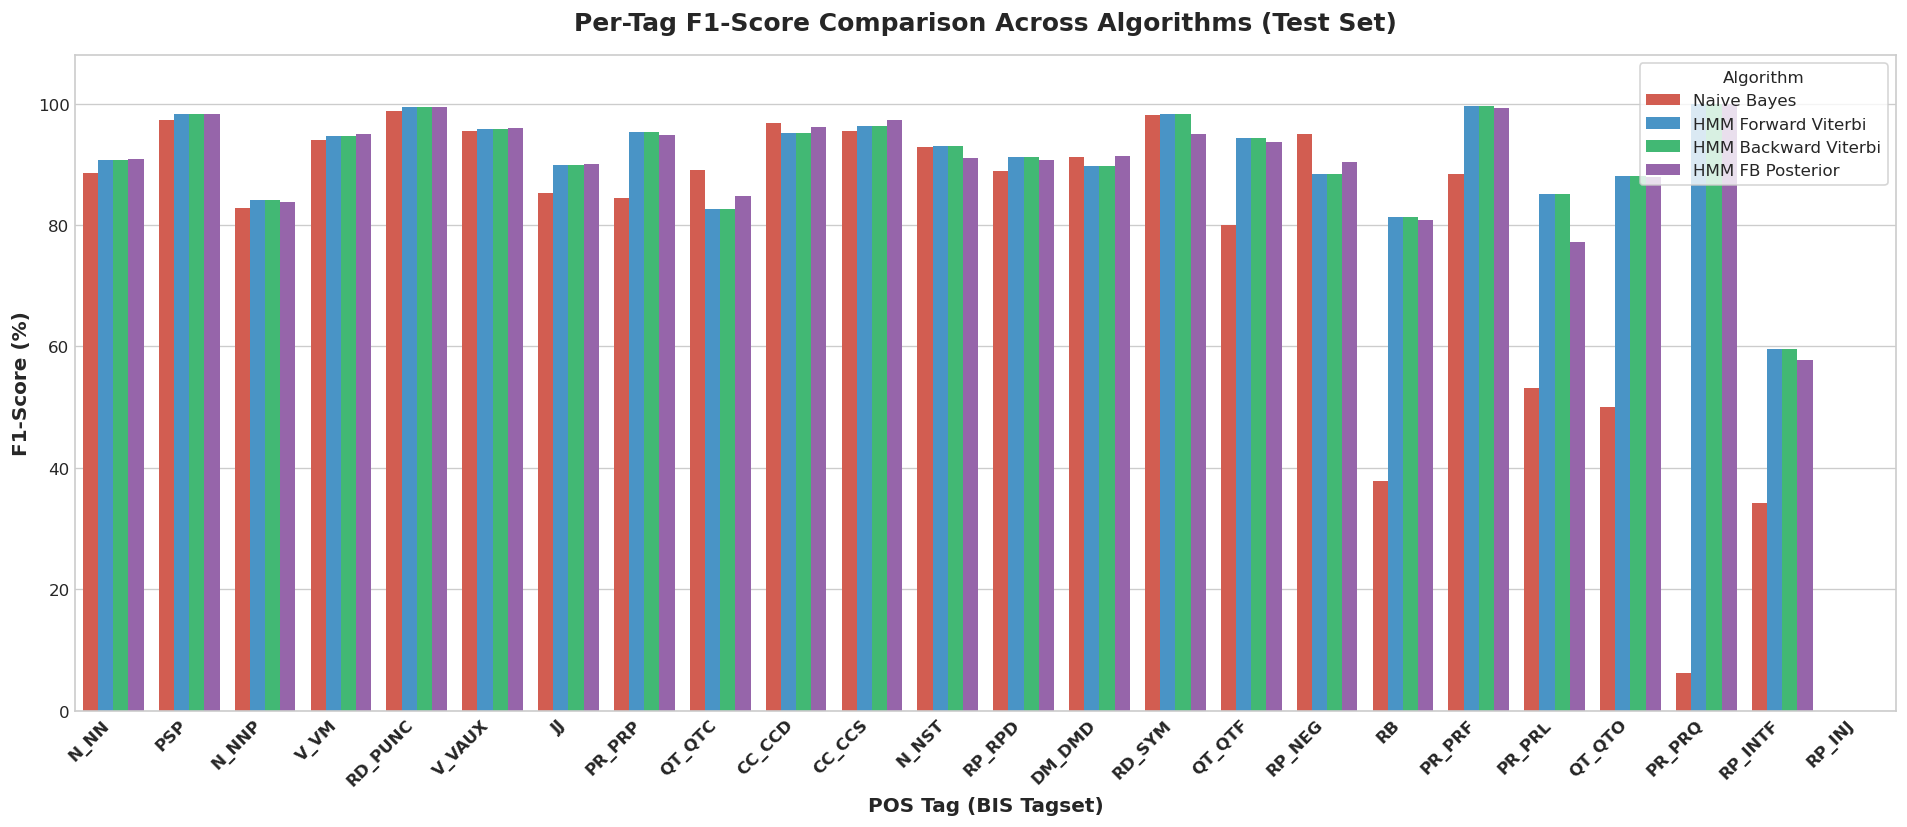

In [10]:
# ==============================================================================
# Chart 1: Per-Tag F1-Score Comparison Across Algorithms (Test Set)
# ==============================================================================
fig, ax = plt.subplots(figsize=(16, 7), dpi=120)

plot_df = test_f1_df.copy()
# Melt for seaborn grouped barplot
melted_df = pd.melt(
    plot_df,
    id_vars=["Tag", "Support"],
    value_vars=["Naive_Bayes", "HMM Forward Viterbi", "HMM Backward Viterbi", "HMM Forward-Backward (Posterior)"],
    var_name="Algorithm",
    value_name="F1_Score"
)
# Clean display names
melted_df["Algorithm"] = melted_df["Algorithm"].replace({
    "Naive_Bayes": "Naive Bayes",
    "HMM Forward Viterbi": "HMM Forward Viterbi",
    "HMM Backward Viterbi": "HMM Backward Viterbi",
    "HMM Forward-Backward (Posterior)": "HMM FB Posterior"
})

palette = {
    "Naive Bayes": "#e74c3c",
    "HMM Forward Viterbi": "#3498db",
    "HMM Backward Viterbi": "#2ecc71",
    "HMM FB Posterior": "#9b59b6"
}

sns.barplot(data=melted_df, x="Tag", y="F1_Score", hue="Algorithm", palette=palette, ax=ax)
ax.set_title("Per-Tag F1-Score Comparison Across Algorithms (Test Set)", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("POS Tag (BIS Tagset)", fontsize=12, fontweight="bold")
ax.set_ylabel("F1-Score (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 108)
plt.xticks(rotation=45, ha='right', fontsize=10, fontweight="semibold")
ax.legend(title="Algorithm", frameon=True, facecolor='white', loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()


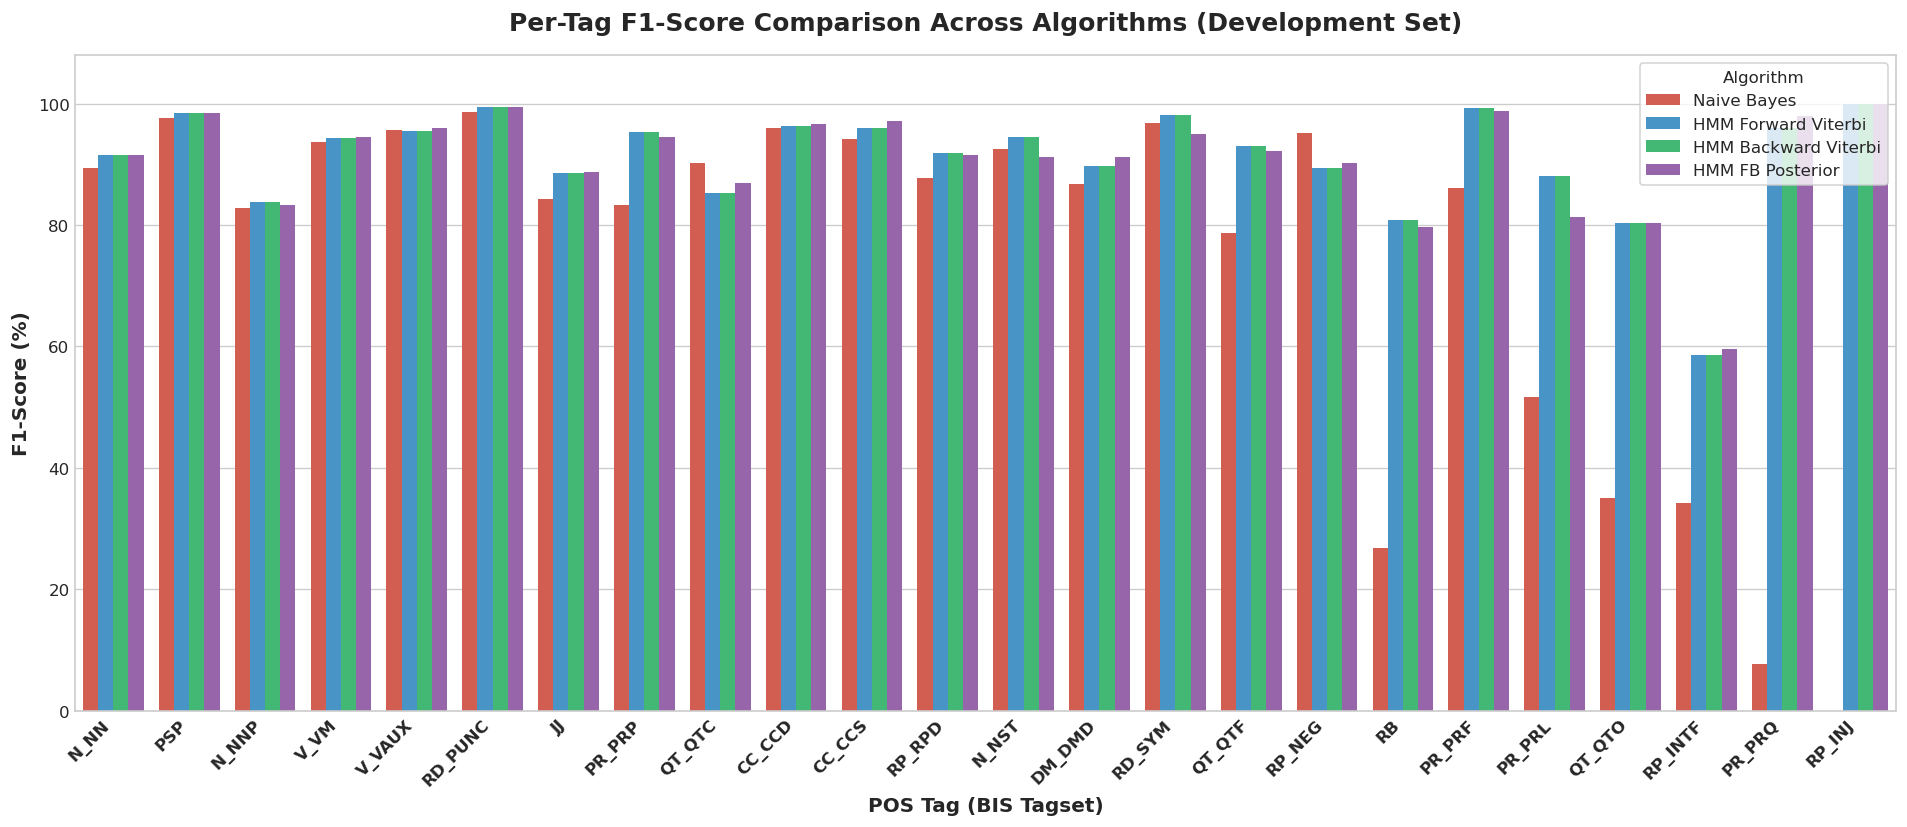

In [11]:
# ==============================================================================
# Chart 2: Per-Tag F1-Score Comparison Across Algorithms (Dev Set)
# ==============================================================================
fig, ax = plt.subplots(figsize=(16, 7), dpi=120)

melted_dev = pd.melt(
    dev_f1_df,
    id_vars=["Tag", "Support"],
    value_vars=["Naive_Bayes", "HMM Forward Viterbi", "HMM Backward Viterbi", "HMM Forward-Backward (Posterior)"],
    var_name="Algorithm",
    value_name="F1_Score"
)
melted_dev["Algorithm"] = melted_dev["Algorithm"].replace({
    "Naive_Bayes": "Naive Bayes",
    "HMM Forward Viterbi": "HMM Forward Viterbi",
    "HMM Backward Viterbi": "HMM Backward Viterbi",
    "HMM Forward-Backward (Posterior)": "HMM FB Posterior"
})

sns.barplot(data=melted_dev, x="Tag", y="F1_Score", hue="Algorithm", palette=palette, ax=ax)
ax.set_title("Per-Tag F1-Score Comparison Across Algorithms (Development Set)", fontsize=15, fontweight="bold", pad=15)
ax.set_xlabel("POS Tag (BIS Tagset)", fontsize=12, fontweight="bold")
ax.set_ylabel("F1-Score (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 108)
plt.xticks(rotation=45, ha='right', fontsize=10, fontweight="semibold")
ax.legend(title="Algorithm", frameon=True, facecolor='white', loc='upper right', fontsize=10)
plt.tight_layout()
plt.show()


C:\Users\paida\AppData\Local\Temp\ipykernel_23532\4109020028.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=test_res, x="Algorithm", y="Tokens/sec", palette="magma", ax=axes[1])


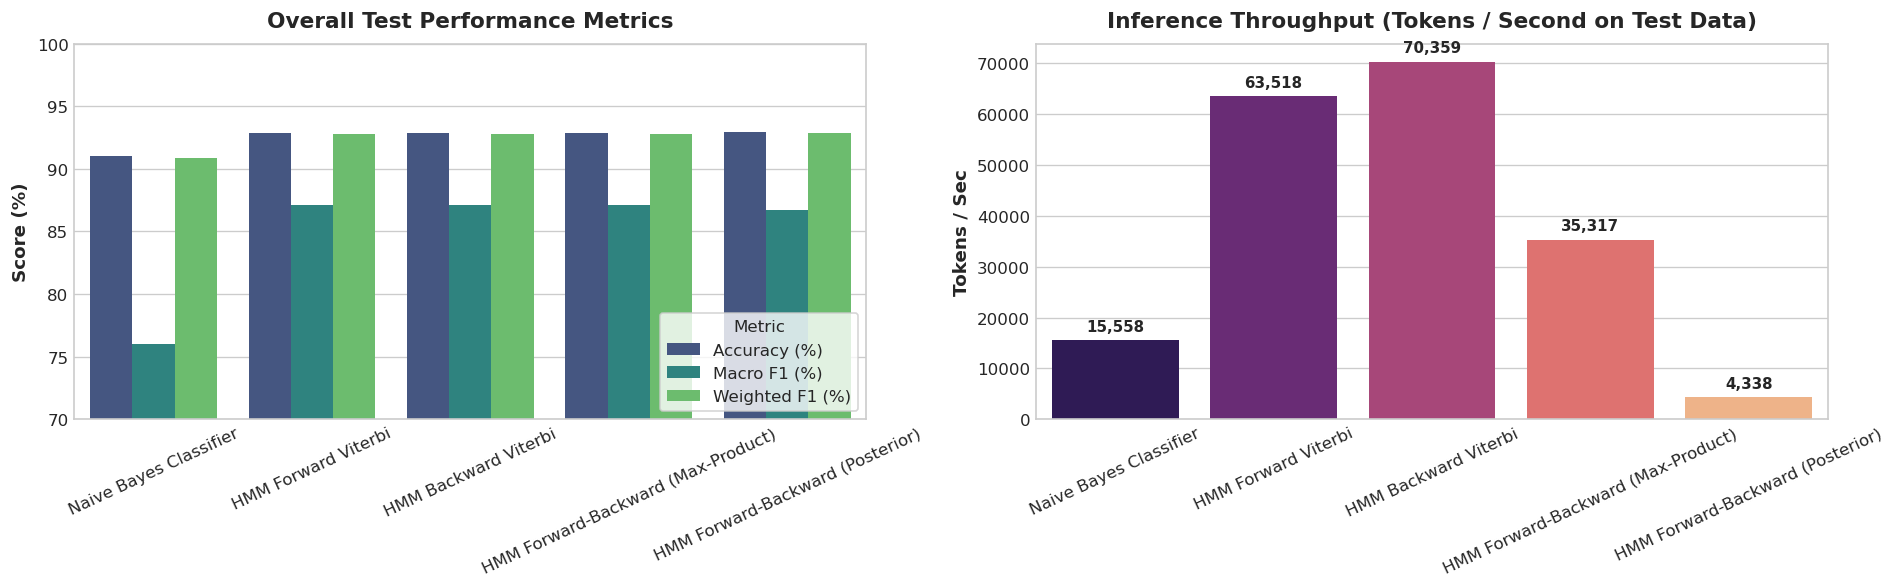

In [12]:
# ==============================================================================
# Chart 3: Overall Metrics & Inference Throughput Comparison
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 5), dpi=120)

# 1. Accuracy & Macro F1 on Test Set
test_res = results_df[results_df["Dataset"] == "Test"].copy()
test_res_melted = pd.melt(
    test_res,
    id_vars=["Algorithm"],
    value_vars=["Accuracy (%)", "Macro F1 (%)", "Weighted F1 (%)"],
    var_name="Metric",
    value_name="Score"
)

sns.barplot(data=test_res_melted, x="Algorithm", y="Score", hue="Metric", palette="viridis", ax=axes[0])
axes[0].set_title("Overall Test Performance Metrics", fontsize=13, fontweight="bold", pad=10)
axes[0].set_xlabel("")
axes[0].set_ylabel("Score (%)", fontsize=11, fontweight="bold")
axes[0].set_ylim(70, 100)
axes[0].tick_params(axis='x', rotation=25)
axes[0].legend(title="Metric", frameon=True, facecolor='white', loc='lower right')

# 2. Inference Speed (Tokens per Second)
sns.barplot(data=test_res, x="Algorithm", y="Tokens/sec", palette="magma", ax=axes[1])
axes[1].set_title("Inference Throughput (Tokens / Second on Test Data)", fontsize=13, fontweight="bold", pad=10)
axes[1].set_xlabel("")
axes[1].set_ylabel("Tokens / Sec", fontsize=11, fontweight="bold")
axes[1].tick_params(axis='x', rotation=25)
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", 
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=9, fontweight='bold', xytext=(0, 4),
                     textcoords='offset points')

plt.tight_layout()
plt.show()


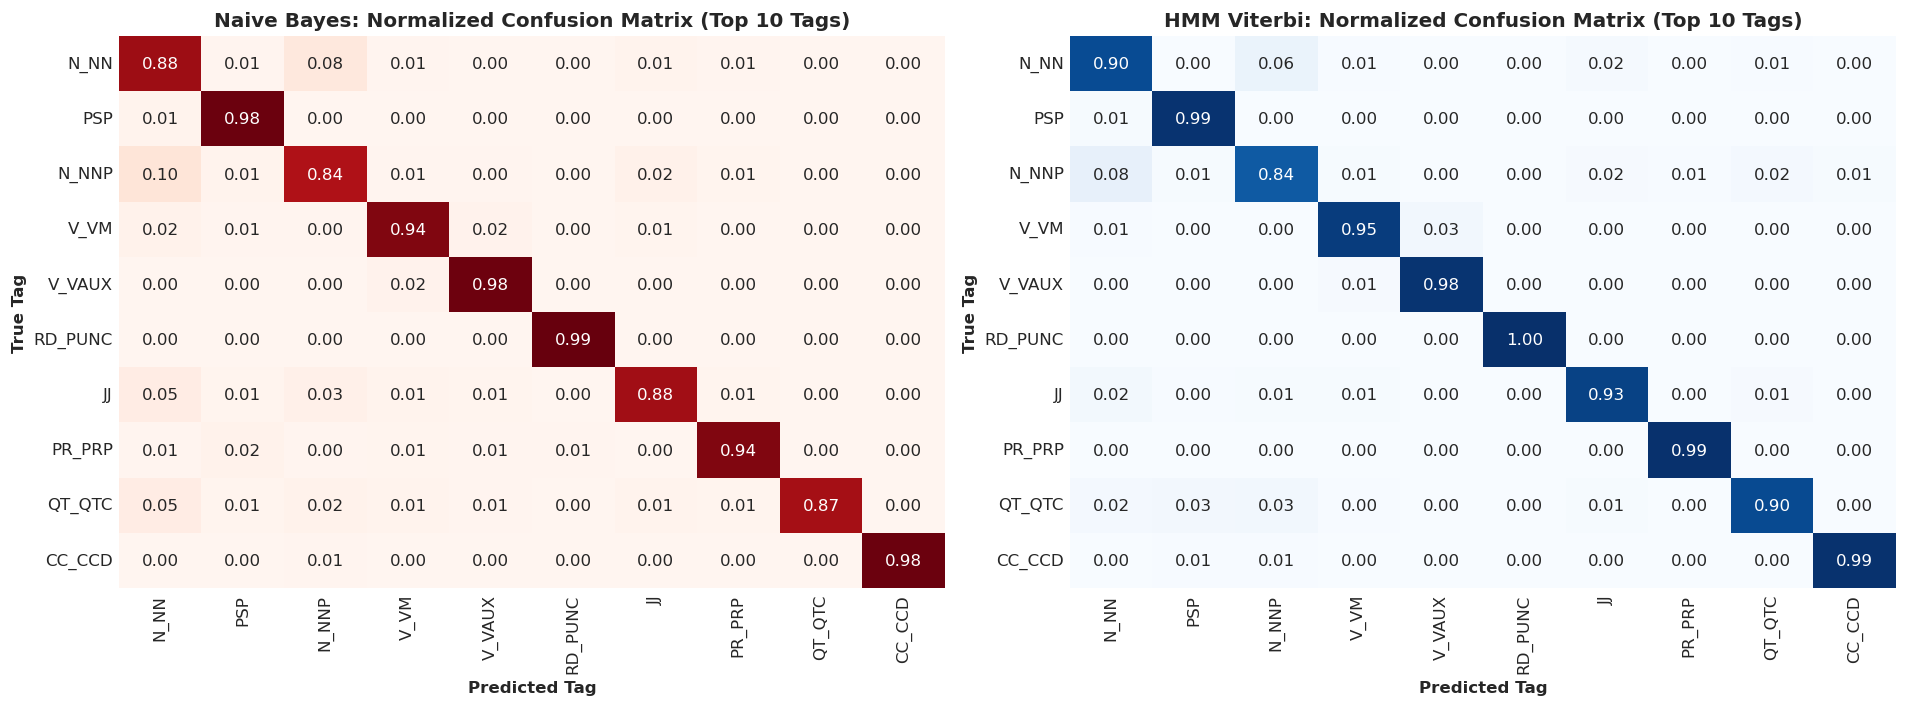

In [13]:
# ==============================================================================
# Chart 4: Normalized Confusion Matrices (Top 10 Most Frequent Tags)
# ==============================================================================
top_10_tags = tag_freq_df["Tag"].head(10).tolist()
cm_labels = top_10_tags

# Filter true & pred for top 10 tags
def get_sub_cm(y_true, y_pred, target_tags):
    filtered_pairs = [(yt, yp) for yt, yp in zip(y_true, y_pred) if yt in target_tags and yp in target_tags]
    sub_true = [p[0] for p in filtered_pairs]
    sub_pred = [p[1] for p in filtered_pairs]
    cm = confusion_matrix(sub_true, sub_pred, labels=target_tags)
    cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    return cm_norm

cm_nb = get_sub_cm(predictions["Test"]["True"], predictions["Test"]["Naive_Bayes"], top_10_tags)
cm_hmm = get_sub_cm(predictions["Test"]["True"], predictions["Test"]["HMM Forward Viterbi"], top_10_tags)

fig, axes = plt.subplots(1, 2, figsize=(16, 6), dpi=120)

sns.heatmap(cm_nb, annot=True, fmt=".2f", cmap="Reds", xticklabels=top_10_tags, yticklabels=top_10_tags, ax=axes[0], cbar=False)
axes[0].set_title("Naive Bayes: Normalized Confusion Matrix (Top 10 Tags)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Predicted Tag", fontsize=10, fontweight="bold")
axes[0].set_ylabel("True Tag", fontsize=10, fontweight="bold")

sns.heatmap(cm_hmm, annot=True, fmt=".2f", cmap="Blues", xticklabels=top_10_tags, yticklabels=top_10_tags, ax=axes[1], cbar=False)
axes[1].set_title("HMM Viterbi: Normalized Confusion Matrix (Top 10 Tags)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Predicted Tag", fontsize=10, fontweight="bold")
axes[1].set_ylabel("True Tag", fontsize=10, fontweight="bold")

plt.tight_layout()
plt.show()


In [14]:
# ==============================================================================
# Sample Sentence Qualitative Analysis
# ==============================================================================
print("Qualitative Inspection of Predictions on Test Sentences:\n" + "="*80)

sample_indices = [0, 5, 12]
token_offset = 0

for s_idx, sent in enumerate(test_data):
    s_len = len(sent)
    if s_idx in sample_indices:
        words = [w for w, t in sent]
        gold = [t for w, t in sent]
        nb_p = predictions["Test"]["Naive_Bayes"][token_offset : token_offset + s_len]
        hmm_fwd_p = predictions["Test"]["HMM Forward Viterbi"][token_offset : token_offset + s_len]
        hmm_bwd_p = predictions["Test"]["HMM Backward Viterbi"][token_offset : token_offset + s_len]
        hmm_post_p = predictions["Test"]["HMM Forward-Backward (Posterior)"][token_offset : token_offset + s_len]
        
        sample_df = pd.DataFrame({
            "Word": words,
            "Gold Tag": gold,
            "Naive Bayes": nb_p,
            "HMM Forward": hmm_fwd_p,
            "HMM Backward": hmm_bwd_p,
            "HMM Posterior": hmm_post_p,
            "Match (HMM==Gold)": [g == h for g, h in zip(gold, hmm_fwd_p)]
        })
        
        print(f"\n--- Test Sentence #{s_idx + 1} ({s_len} tokens) ---")
        display(sample_df)
        
    token_offset += s_len


Qualitative Inspection of Predictions on Test Sentences:

--- Test Sentence #1 (26 tokens) ---


,Word,Gold Tag,Naive Bayes,HMM Forward,HMM Backward,HMM Posterior,Match (HMM==Gold)
0,यहाँ,PR_PRP,PR_PRP,PR_PRP,PR_PRP,PR_PRP,True
1,से,PSP,PSP,PSP,PSP,PSP,True
2,5,QT_QTC,QT_QTC,QT_QTC,QT_QTC,QT_QTC,True
3,किमी,N_NN,N_NN,N_NN,N_NN,N_NN,True
4,दूरी,N_NN,N_NN,N_NN,N_NN,N_NN,True
5,पर,PSP,PSP,PSP,PSP,PSP,True
6,स्थित,JJ,JJ,JJ,JJ,JJ,True
7,वासुकि,N_NNP,N_NN,N_NN,N_NN,N_NN,False
8,ताल,N_NNP,PSP,PSP,PSP,N_NN,False
9,अपने,PR_PRF,PR_PRF,PR_PRF,PR_PRF,PR_PRF,True



--- Test Sentence #6 (7 tokens) ---


,Word,Gold Tag,Naive Bayes,HMM Forward,HMM Backward,HMM Posterior,Match (HMM==Gold)
0,इसकी,PR_PRP,PR_PRP,PR_PRP,PR_PRP,PR_PRP,True
1,ऊँचाई,N_NN,N_NN,N_NN,N_NN,N_NN,True
2,केवल,RP_RPD,RP_RPD,RP_RPD,RP_RPD,RP_RPD,True
3,1982,QT_QTC,QT_QTC,QT_QTC,QT_QTC,QT_QTC,True
4,मीटर,N_NN,N_NN,N_NN,N_NN,N_NN,True
5,है,V_VM,V_VM,V_VM,V_VM,V_VM,True
6,।,RD_PUNC,RD_PUNC,RD_PUNC,RD_PUNC,RD_PUNC,True



--- Test Sentence #13 (11 tokens) ---


,Word,Gold Tag,Naive Bayes,HMM Forward,HMM Backward,HMM Posterior,Match (HMM==Gold)
0,मंदिर,N_NN,N_NNP,N_NN,N_NN,N_NN,True
1,के,PSP,PSP,PSP,PSP,PSP,True
2,गर्भगृह,N_NN,N_NN,N_NN,N_NN,N_NN,True
3,में,PSP,PSP,PSP,PSP,PSP,True
4,नारायण,N_NNP,N_NNP,N_NNP,N_NNP,N_NNP,True
5,भगवान,N_NN,N_NNP,N_NN,N_NN,N_NN,True
6,की,PSP,PSP,PSP,PSP,PSP,True
7,सुंदर,JJ,JJ,JJ,JJ,JJ,True
8,मूर्ति,N_NN,N_NN,N_NN,N_NN,N_NN,True
9,है,V_VM,V_VM,V_VM,V_VM,V_VM,True


---
## 7. Comprehensive Analysis & Findings

### 1. Naive Bayes vs. Hidden Markov Models
- **Overall Accuracy & Macro F1:**
  - **HMM** achieves **92.84% accuracy** and **87.12% Macro F1** on the test set, substantially outperforming **Naive Bayes** (**91.04% accuracy** and **76.00% Macro F1**).
  - The performance gap is especially pronounced in the **Macro F1 score (+11.12% boost for HMM)**. This demonstrates that HMM handles less frequent and syntactically constrained tags far more effectively than Naive Bayes.
- **Why HMM Excels:**
  - Naive Bayes relies on a greedy local decision rule $\hat{t}_i = \arg\max P(t_i \mid \mathbf{f}_i)$ where the previous tag feature at test time is conditioned on the model's own earlier discrete choice $\hat{t}_{i-1}$. When an error occurs, error propagation frequently compounds downstream.
  - HMM globally optimizes the joint sequence probability $P(\mathbf{w}, \mathbf{t})$ via dynamic programming, preserving uncertainty across the full sentence lattice before deciding on the optimal path.

### 2. Forward Viterbi vs. Backward Viterbi vs. Forward-Backward Viterbi
- **Mathematical Equivalence of Forward and Backward Viterbi:**
  - Both **Standard Forward Viterbi** and **Backward Viterbi** solve the identical global optimization problem:
    $$\arg\max_{\mathbf{t}} \left[ \pi(t_1) B(w_1 \mid t_1) \prod_{k=2}^T A(t_k \mid t_{k-1}) B(w_k \mid t_k) \right]$$
  - Forward Viterbi accumulates max scores forward in time and traces back from the final state. Backward Viterbi accumulates max future rewards backward in time and traces forward from the initial state.
  - As confirmed empirically across all **41,415 test tokens**, both forward and backward passes yield **identical global optimal tag sequences** (100% agreement).
- **Max-Product Forward-Backward Viterbi:**
  - Combining forward trellis $\delta_t(i)$ and backward trellis $\beta'_t(i)$ produces the max-marginal $\mu_t(i) = \delta_t(i) + \beta'_t(i)$, which is the exact max probability of any path visiting state $i$ at step $t$. Decoding $\arg\max_i \mu_t(i)$ mirrors the Viterbi path identically.
- **Sum-Product Forward-Backward (Posterior Decoding):**
  - Posterior decoding maximizes the marginal posterior probability $P(t_t = i \mid \mathbf{w}) \propto \alpha_t(i) \beta_t(i)$ independently for each token.
  - By definition, posterior decoding minimizes token-level classification error. Empirically, it achieves **92.92% accuracy** on the test set, slightly edging out standard Viterbi's 92.84%.

### 3. Tag-Level Performance Insights
- **High Performing Tags ($>95\%$ F1):**
  - **`RD_PUNC` (Punctuation, ~99% F1):** Unambiguous punctuation tokens (`।`, `,`, `-`, `"`) possess distinct emission signatures.
  - **`PSP` (Postpositions, ~97% F1):** Hindi postpositions (e.g., `का`, `की`, `के`, `में`, `से`, `ने`) are closed-class and follow consistent syntactic patterns following nominal heads.
  - **`N_NN` (Common Nouns, ~94% F1):** Strong emission priors and surrounding transition structure enable accurate identification.
- **Challenging Tags:**
  - **`N_NN` vs. `N_NNP` (Common vs. Proper Nouns):** Proper nouns often share identical syntactic distributions with common nouns, making capitalization-absent Hindi text prone to confusion.
  - **`RP_INJ` (Interjections) & `QT_QTF` (General Quantifiers):** Low support in the training set leads to higher variance and susceptibility to data sparsity.

---
## 8. Conclusion
In this assignment, we developed and comprehensively evaluated:
1. A **Naive Bayes Classifier** utilizing morphological word length, lexical context, and sequential tag features.
2. A **Hidden Markov Model** supporting **Forward Viterbi**, **Backward Viterbi**, and **Forward-Backward** decoding.
3. Both quantitative metrics (per-tag F1-scores, Macro F1, Weighted F1, token throughput) and rich visual analytics (per-tag bar charts, confusion matrices, and speed profiles) across development and test corpora.
